# BRENDA kinetics — source overview

This notebook inspects the complete normalized EC 3.4 kinetic inventory before
acceptance filtering. It retains every organism and substrate label. There is
no MEROPS matching, sequence search or enrichment from half-life/cut-window data.

**One source context is not an independently established experiment.** Separate
BRENDA parameter entries are not paired merely because they share a PMID,
protein or substrate. The [contract and diagram](../../../../../../tools/proteolysis_data_manager/docs/KINETICS_CONTRACT.md)
define all tables and links. Detailed entry decisions are in
`data/kinetics_datasets/normalized/remarks_brenda.md`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "assets/tools/proteolysis_data_manager").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.kinetics.reader import load_kinetics_data
from proteolysis_data_manager.analysis.kinetics.overview import (
    table_inventory, missingness, species_coverage, parameter_summary,
    formatted_table, plot_parameters, plot_conditions,
)
DATA_ROOT = ROOT / "data/kinetics_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_kinetics"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .12})
def table(frame, limit=30):
    if len(frame) > limit:
        print(f"Preview: {limit} of {len(frame)} rows")
    display(HTML(formatted_table(frame, limit)))
def figure(fig):
    plt.show()
    plt.close(fig)

In [2]:
dataset = load_kinetics_data(DATA_ROOT)
view = dataset.measurements_view()
manifest = dataset.metadata
assert len(view) == len(dataset["kinetic_measurements"])
assert view.measurement_id.is_unique
table(table_inventory(dataset))
table(pd.DataFrame([{"source": "brenda", "release": manifest["source_version"],
    "raw_kinetic_entries": manifest["raw_kinetic_entries"],
    "retained_measurements": len(view), "source_contexts": len(dataset["experiments"]),
    "EC_blocks_with_measurements": manifest["ec_blocks_with_measurements"]}]))
assert len(view) == manifest["raw_kinetic_entries"]

table,rows,columns
enzymes,4048,9
substrates,7517,12
experiments,26697,14
experiment_enzymes_relation,26743,3
experiment_substrates_relation,26697,2
kinetic_measurements,26697,13
cleavage_sites,0,13
measurement_cleavage_sites_relation,0,2


source,release,raw_kinetic_entries,retained_measurements,source_contexts,EC_blocks_with_measurements
brenda,2026.1,26697,26697,26697,327


## Source organisms and sample conditions

Organism groups below refer to the **enzyme**, not the assay sample. One source
entry may link several organisms; species coverage therefore can overlap.
The current adapter does not turn an enzyme's tissue or organism into serum
metadata. It also does not infer in-vitro mode from a kinetic-parameter label.

Preview: 40 of 496 rows


enzyme_species,source_contexts,measurements,numeric,non_numeric
Homo sapiens,8435,8435,8195,240
Rattus norvegicus,1573,1573,1527,46
Sus scrofa,1144,1144,1108,36
Bos taurus,1131,1131,1078,53
Escherichia coli,793,793,768,25
Mus musculus,663,663,643,20
Saccharomyces cerevisiae,449,449,438,11
Plasmodium falciparum,425,425,420,5
Trypanosoma cruzi,355,355,353,2
Human immunodeficiency virus 1,331,331,327,4


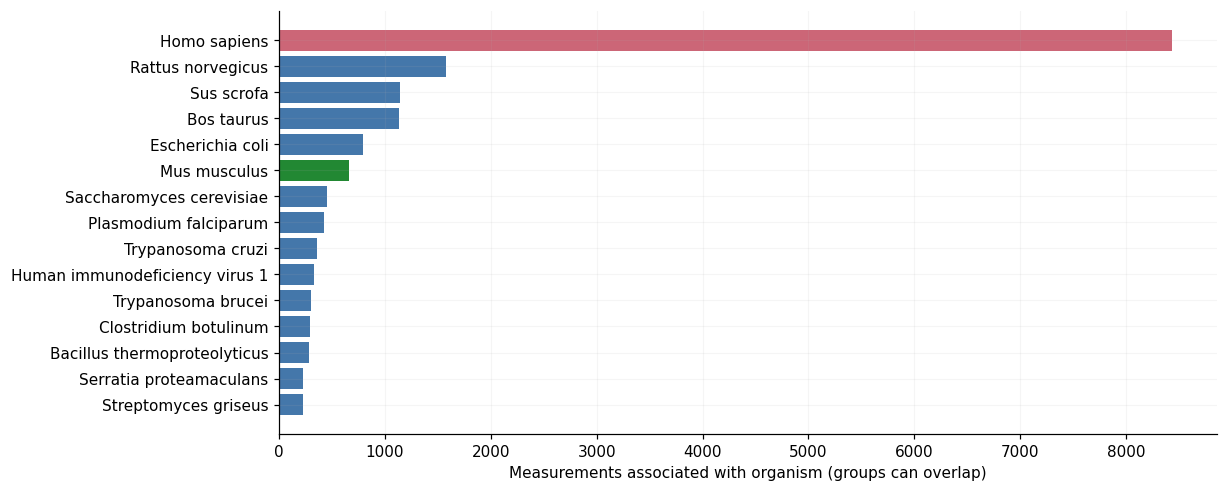

species,matrix,in_vivo_in_vitro,source_contexts
None,None,None,26697


In [3]:
coverage = species_coverage(dataset)
table(coverage, 40)
top = coverage.head(15)
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#CC6677" if s == "Homo sapiens" else "#228833" if s == "Mus musculus" else "#4477AA" for s in top.enzyme_species]
ax.barh(top.enzyme_species.iloc[::-1], top.measurements.iloc[::-1], color=colors[::-1])
ax.set(xlabel="Measurements associated with organism (groups can overlap)")
figure(fig)
exp = dataset["experiments"]
table(exp.groupby(["species", "matrix", "in_vivo_in_vitro"], dropna=False).size().rename("source_contexts").reset_index())

## Documentation and missingness

Missing chemistry is retained for a later, separately reviewed update across
independent data families. Names such as reporter substrates or protein names
are not automatically converted into peptide sequences. Null conditions are
not filled with physiological references.

table,field,missing,total,missing_percent
substrates,substrate_id,0,7517,0
substrates,source,0,7517,0
substrates,source_record_id,0,7517,0
substrates,name_reported,0,7517,0
substrates,substrate_type,3314,7517,44.09
substrates,sequence,7517,7517,100
substrates,sequence_length,7517,7517,100
substrates,chirality,7517,7517,100
substrates,topology,7517,7517,100
substrates,n_terminal_modification,7517,7517,100


source_label_type,dictionary_entries
unresolved,3314
synthetic_substrate,2205
peptide,1901
protein,97


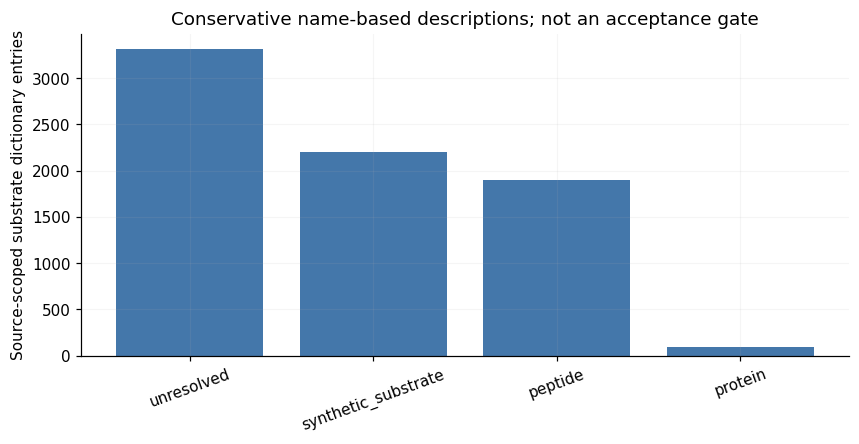

In [4]:
gaps = missingness(dataset)
table(gaps[gaps.table.isin(["experiments", "substrates", "kinetic_measurements"])], 60)
type_counts = dataset["substrates"].substrate_type.fillna("unresolved").value_counts().rename_axis("source_label_type").reset_index(name="dictionary_entries")
table(type_counts)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(type_counts.source_label_type, type_counts.dictionary_entries, color="#4477AA")
ax.set(ylabel="Source-scoped substrate dictionary entries", title="Conservative name-based descriptions; not an acceptance gate")
ax.tick_params(axis="x", rotation=20)
figure(fig)

## Kinetic parameter values and reported conditions

The three parameter types have different dimensions and are shown separately.
Axes display physical numerical values, with logarithmic spacing. Only positive
reported numerical points enter these histograms; the tables also count missing,
bounded and interval results. Ordinary ranges are not midpoint labels or CI.

parameter,unit,measurements,numeric,non_numeric,min,median,max
kcat,s^-1,10639,10378,261,5.83e-10,4.7,9.1e+05
kcat_km,M^-1 s^-1,2974,2951,23,0.00065,4.7e+04,2.5e+10
km,M,13084,12576,508,2.42e-10,7.2e-05,1.3


parameter_type,value_relation,measurements
kcat,eq,10378
kcat,range,121
kcat,unknown,140
kcat_km,eq,2951
kcat_km,range,4
kcat_km,unknown,19
km,eq,12576
km,range,83
km,unknown,425


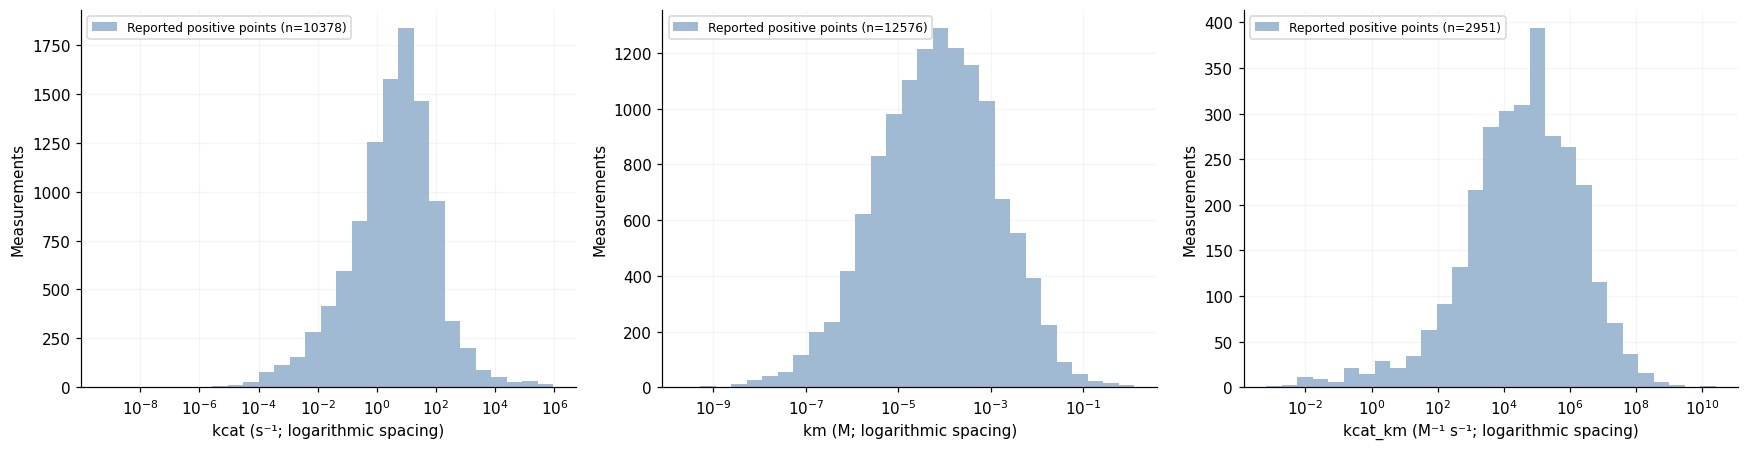

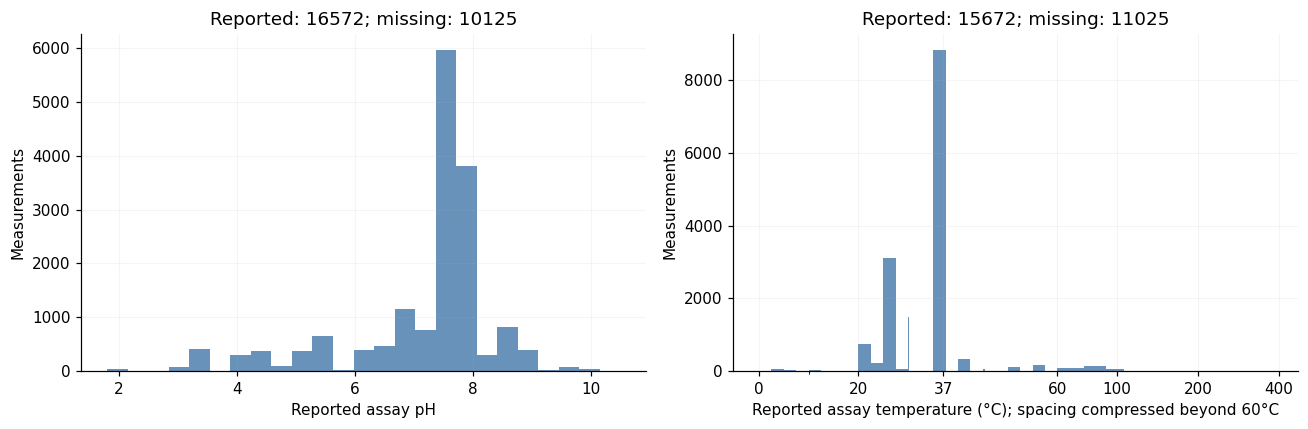

temperature_c,conditions_raw,source_record_id
378,"pH 4.0, 378°C, mutant enzyme E77A","[{'source': 'brenda', 'id': 'data/3.4.14.9/turnover_number/26'}]"


field,reported_measurements,missing_measurements
ph,16572,10125
temperature_c,15672,11025
sd,0,26697
ci_lower,0,26697
ci_upper,0,26697
replicate_count,0,26697


In [5]:
table(parameter_summary(view))
table(view.groupby(["parameter_type", "value_relation"], dropna=False).size().rename("measurements").reset_index())
figure(plot_parameters(view))
figure(plot_conditions(view))
table(view.loc[view.temperature_c.gt(150) | view.temperature_c.lt(-20), ["temperature_c", "conditions_raw", "source_record_id"]], 20)
table(pd.DataFrame([{"field": c, "reported_measurements": int(view[c].notna().sum()),
    "missing_measurements": int(view[c].isna().sum())} for c in ["ph", "temperature_c", "sd", "ci_lower", "ci_upper", "replicate_count"]]))

## Publications, relationships and cleavage documentation

PubMed links come directly from source reference metadata. They do not establish
common experimental conditions. Group protein links stay unresolved.

The kinetic families do not provide structured cleavage-site fields. Empty
site tables mean **no structured annotations extracted**, not that no cleavage
occurred or no site is mentioned elsewhere. Free-text comments remain available
for the separate source-context audit. No fragments are localized here.

In [6]:
publications = exp[["publication_id", "publication_urls"]].head(20)
table(publications)
urls = sorted({url for values in exp.publication_urls.dropna() for url in values})
display(HTML("<p>Example source references: " + ", ".join(f'<a href="{url}">{url.rsplit("/", 2)[-2]}</a>' for url in urls[:12]) + "</p>"))
links = dataset["experiment_enzymes_relation"]
table(links.enzyme_link_status.value_counts().rename_axis("link_status").reset_index(name="relation_rows"))
assert len(dataset["kinetic_measurements"]) == len(view)
table(pd.DataFrame([{"reported_site_rows_extracted": len(dataset["cleavage_sites"]),
    "measurement_site_links": len(dataset["measurement_cleavage_sites_relation"]),
    "missing_substrate_measurements": int(view.substrate_id.isna().sum()),
    "source_contexts_with_pubmed": int(exp.publication_urls.map(lambda v: v is not None and len(v) > 0).sum())}]))

publication_id,publication_urls
[PMID:8982850],[https://pubmed.ncbi.nlm.nih.gov/8982850/]
[brenda:3.4.11.1:reference:165],None
[brenda:3.4.11.1:reference:165],None
[brenda:3.4.11.1:reference:165],None
[brenda:3.4.11.1:reference:165],None
[brenda:3.4.11.1:reference:165],None
[brenda:3.4.11.1:reference:165],None
[PMID:26075721],[https://pubmed.ncbi.nlm.nih.gov/26075721/]
[PMID:26075721],[https://pubmed.ncbi.nlm.nih.gov/26075721/]
[PMID:26075721],[https://pubmed.ncbi.nlm.nih.gov/26075721/]


link_status,relation_rows
direct,26498
reported_group_unresolved,245


reported_site_rows_extracted,measurement_site_links,missing_substrate_measurements,source_contexts_with_pubmed
0,0,0,25499


## Review before a source protocol

The next notebook audits ambiguous entries and discarded condition interpretations.
The first protocol selects uniquely human enzyme contexts, without asserting serum.
pH/T thresholds remain disabled until their distributions and documentation are
reviewed. No numerical, class or CI values are synthesized.